In [10]:
# %%
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [11]:

# 1. Carrega os arquivos CSV
df_items_pedido = pd.read_csv('../../Dados/Brazilian Logistic/olist_order_items_dataset.csv')
df_pedidos = pd.read_csv('../../Dados/Brazilian Logistic/olist_orders_dataset.csv')
df_pagamentos_pedido = pd.read_csv('../../Dados/Brazilian Logistic/olist_order_payments_dataset.csv')
df_revisoes_pedido = pd.read_csv('../../Dados/Brazilian Logistic/olist_order_reviews_dataset.csv')
df_produtos = pd.read_csv('../../Dados/Brazilian Logistic/olist_products_dataset.csv')

# %%
# Problema: Alguns pedidos possuem mais de um vendedor, o que pode gerar inconsistências na análise de reviews. 
# Para garantir que cada pedido seja associado a apenas um vendedor, filtramos os pedidos que possuem apenas um vendedor.

df_items_pedido_filtrado = df_items_pedido.groupby('order_id').filter(lambda x: x['seller_id'].nunique() == 1)
df_items_pedido_filtrado['qtd_items'] = df_items_pedido_filtrado.groupby('order_id')['order_id'].transform('count')

df = df_items_pedido_filtrado.merge(df_revisoes_pedido.drop_duplicates(subset='order_id', keep='last'), how='left', on='order_id')
df = df.merge(df_pedidos, how='left', on='order_id')

# Calcular dias de atraso e diferença de data de entrega registrada pelo vendedor e cliente
# Se um pedido teve registro de entrega pelo cliente mas não pelo vendedor, subtrair pela média da diferença de data de entrega entre vendedor e cliente
# OBS: se tiver alguma data de entrega (vendedor ou cliente) é nula, o resultado será nulo
from datetime import datetime
df['dias_atraso'] = (pd.to_datetime(df['order_delivered_carrier_date']) - pd.to_datetime(df['order_estimated_delivery_date'])).dt.days
df['diferenca_data_entrega_vendedor_cliente'] = (pd.to_datetime(df['order_delivered_customer_date']) - pd.to_datetime(df['order_delivered_carrier_date'])).dt.days
media_diferenca = df['diferenca_data_entrega_vendedor_cliente'].filter(lambda x: x.notnull()).mean()
condicao = (df['dias_atraso'].isnull() & df['order_delivered_customer_date'].notnull())
df.loc[condicao, 'order_delivered_carrier_date'] = (pd.to_datetime(df.loc[condicao, 'order_delivered_customer_date']) - pd.Timedelta(days=media_diferenca.round())).dt.strftime('%Y-%m-%d %H:%M:%S')

# Remove pedidos que não possuem nem comentários nem registro de data de entrega, e remove avaliações duplicadas, evitando viés nos dados.
# Tratar avaliações repetidas, filtrando pela avaliação mais longa
df['review_comment'] = df['review_comment_title'].fillna("") + ': ' + df['review_comment_message'].fillna("")
df['review_char_length'] = df['review_comment'].str.len()
df = df.sort_values('review_char_length', ascending=False).drop_duplicates('order_id', keep='first')
df = df[(df['review_char_length'] > 2) | (df['order_delivered_carrier_date'].notna() | df['order_delivered_customer_date'].notna())]

df_geolocalizacao = pd.read_csv('../../Dados/Brazilian Logistic/olist_geolocation_dataset.csv')
df_clientes = pd.read_csv('../../Dados/Brazilian Logistic/olist_customers_dataset.csv')
df_vendedores = pd.read_csv('../../Dados/Brazilian Logistic/olist_sellers_dataset.csv')

# 1. Carregar os datasets auxiliares
df_geolocalizacao = pd.read_csv('../../Dados/Brazilian Logistic/olist_geolocation_dataset.csv')
df_clientes = pd.read_csv('../../Dados/Brazilian Logistic/olist_customers_dataset.csv')
df_vendedores = pd.read_csv('../../Dados/Brazilian Logistic/olist_sellers_dataset.csv')

# 2. Normalizar os CEPs para garantir correspondência
def normalizar_cep(coluna):
    return (coluna.astype('string').str.replace(r'\.0$', '', regex=True).str.zfill(5))

df_geolocalizacao['geolocation_zip_code_prefix'] = normalizar_cep(df_geolocalizacao['geolocation_zip_code_prefix'])
df_clientes['customer_zip_code_prefix'] = normalizar_cep(df_clientes['customer_zip_code_prefix'])
df_vendedores['seller_zip_code_prefix'] = normalizar_cep(df_vendedores['seller_zip_code_prefix'])

# 3. Agrupar geolocalização por CEP
# Evita duplicações de linhas no merge
df_geo = (df_geolocalizacao.groupby('geolocation_zip_code_prefix', as_index=False).agg({'geolocation_lat': 'mean', 'geolocation_lng': 'mean'}))

# Integra CEPs de clientes e vendedores
df = df.merge(df_clientes[['customer_id', 'customer_zip_code_prefix']], on='customer_id', how='left').merge(df_vendedores[['seller_id', 'seller_zip_code_prefix']], on='seller_id', how='left')
# Coordenadas dos clientes e vendedores
df = df.merge(df_geo.rename(columns={'geolocation_zip_code_prefix': 'customer_zip_code_prefix', 'geolocation_lat': 'customer_latitude', 'geolocation_lng': 'customer_longitude'}), on='customer_zip_code_prefix', how='left'
).merge(df_geo.rename(columns={'geolocation_zip_code_prefix': 'seller_zip_code_prefix', 'geolocation_lat': 'seller_latitude', 'geolocation_lng': 'seller_longitude'}), on='seller_zip_code_prefix', how='left')

# Conferência das coordenadas
print(df[['customer_latitude', 'customer_longitude', 'seller_latitude', 'seller_longitude']].head())
# 9. Salvar o dataset
df.to_csv('order_items_reviews_filtered.csv', index=False, encoding='utf-8')
# passando pra csv d
df.to_csv('order_items_reviews_filtered.csv')


   customer_latitude  customer_longitude  seller_latitude  seller_longitude
0         -12.945584          -38.381686       -22.914020        -47.013535
1         -14.822631          -39.034230       -23.634903        -46.564837
2         -15.807766          -43.309268       -21.757321        -48.829744
3         -23.383802          -46.323443       -23.453324        -46.539934
4         -12.992588          -38.453968       -23.634607        -46.735882


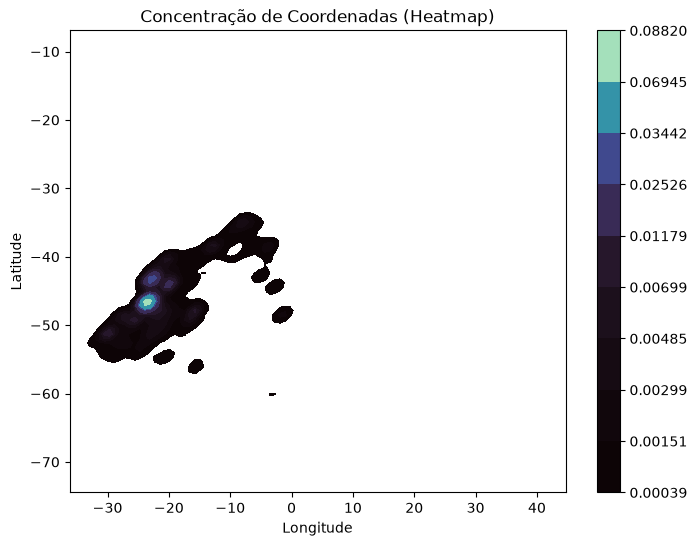

In [ ]:
# 1. Dados de exemplo (Substitua pelo seu df[['lat', 'lng']])
df = df[['customer_latitude', 'customer_longitude']].dropna()
# 2. Criar o mapa de calor com Seaborn
plt.figure(figsize=(8, 6))
sns.kdeplot(data=df,x="customer_latitude", y="customer_longitude", gridsize=100,fill=True,thresh=0.05,cmap="mako",cbar=True)
# 3. Ajustes visuais
plt.title("Concentração de Coordenadas (Heatmap)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()


In [ ]:


# Treinar uma RNN (LSTM no caso) para classificar comentários como: no prazo ou atrasado
# código...

# Embora os cálculos de dias de atraso estimem prazo, o cliente pode ter recebido antes ou depois, portanto, sobrescreveremos pela classificação da LSTM
def classify_review(row):
    return LSTM.predict(row['review_comment']) if row['review_char_length'] > 2 else row['status_entrega']
NO_PRAZO = 0
ATRASADO = 1
NAO_INFORMADO = 2
df['status_entrega'] = df.apply(lambda row: NO_PRAZO if row['dias_atraso'] <= 0 else ATRASADO if row['dias_atraso'] > 0 else NAO_INFORMADO, axis=1)
df['status_entrega'] = df.apply(classify_review, axis=1)


# Treinar uma ML (supervisionada) para identificar padrões prazo pela distancia entre vendedor e comprador 
# código

# Treinar 6 clusters (IA não supervisionada) para classificar prazo por regiões do brasil
# código


